<div style="background-color: #F0FDFF; border: 2px solid #8CCFD1; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">
    
<div style="border-left: 4px solid #8CCFD1; padding-left: 15px; margin: 15px 0;"> 
    
# ПРОЕКТ: Определение возраста покупателей

<div style="background-color: #F0FDFF; border: 2px solid #8CCFD1; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">
    
    
## ОПИСАНИЕ ПРОЕКТА

---

**з а к а з ч и к**: Сетевой супермаркет «Хлеб-Соль»

**ц е л ь**: *Определить возраст покупателей по фотографии*, чтобы анализировать покупки и предлагать товары, соответствующие возрастной группе, а также контролировать добросовестность кассиров при продаже алкоголя.
    
**з а д а ч и**:

**1.** Провести исследовательский анализ набора фотографий.

**2.** Подготовить данные к обучению.

**3.** Обучить нейронную сеть и рассчитать её качество.

---

ОПИСАНИЕ ДАННЫХ

- **`file_name`** — имя файла с изображением.
- **`real_age`** — возраст человека на фотографии (целевая переменная).

Данные взяты с сайта ChaLearn Looking at People. В распоряжении одна папка со всеми изображениями (`/final_files`) и CSV-файл `labels.csv`.

---

КРИТЕРИИ УСПЕХА

<div style="border-left: 4px solid #8CCFD1; padding-left: 15px; margin: 15px 0;"> 

Значение метрики **MAE** на тестовой выборке должно быть **не больше 8**.

</div>

<div style="border-left: 4px solid #8CCFD1; padding-left: 15px; margin: 15px 0;"> 

### Импорты и загрузка данных

In [2]:
# Стандартная библиотека Python
import os
import warnings
warnings.filterwarnings('ignore')

# Анализ данных и визуализация
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Глубокое обучение
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.applications.resnet import ResNet50
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

In [3]:
# Загружаем данные
labels = pd.read_csv('/datasets/faces/labels.csv')

print('--'*20)
print(f"РАЗМЕР ВЫБОРКИ: {len(labels)} записей")
print('--'*20)

print(f"КОЛОНКИ: {labels.columns.tolist()}")
print('--'*20)
print("\nПЕРВЫЕ 5 ЗАПИСЕЙ:")
print('--'*20)
print(labels.head())

print("\nИНФОРМАЦИЯ О ДАННЫХ:")
print('--'*20)
print(labels.info())

print("\nСТАТИСТИКА:")
print('--'*20)
print(labels['real_age'].describe())

----------------------------------------
РАЗМЕР ВЫБОРКИ: 7591 записей
----------------------------------------
КОЛОНКИ: ['file_name', 'real_age']
----------------------------------------

ПЕРВЫЕ 5 ЗАПИСЕЙ:
----------------------------------------
    file_name  real_age
0  000000.jpg         4
1  000001.jpg        18
2  000002.jpg        80
3  000003.jpg        50
4  000004.jpg        17

ИНФОРМАЦИЯ О ДАННЫХ:
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7591 entries, 0 to 7590
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   file_name  7591 non-null   object
 1   real_age   7591 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 118.7+ KB
None

СТАТИСТИКА:
----------------------------------------
count    7591.000000
mean       31.201159
std        17.145060
min         1.000000
25%        20.000000
50%        29.000000
75%        41.000000
max       100.000000
Name:

КОММЕНТАРИЙ:

- `Размер выборки`: 7591 изображений
- `Столбцы`: file_name, real_age
- `Возраст` от 1 до 100 лет
- `Средний возраст`: ~31 год
- `Медиана`: 29 лет

<div style="border-left: 4px solid #8CCFD1; padding-left: 15px; margin: 15px 0;"> 

## Исследовательский анализ данных

### Статистика и распределение данных

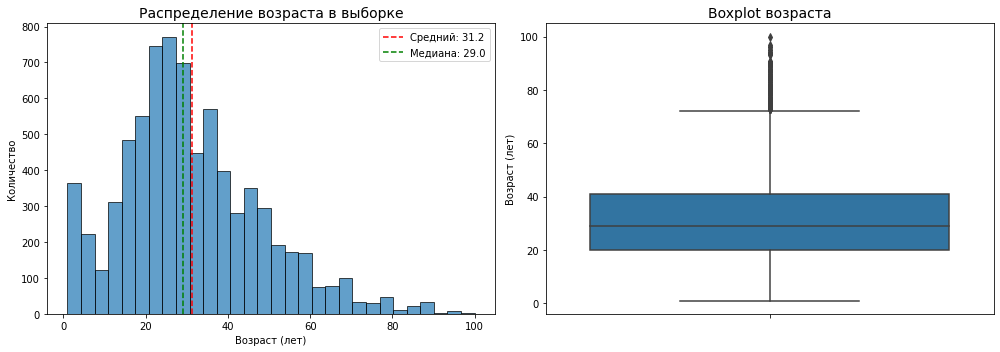


------------------------------------------------------------
РАСПРЕДЕЛЕНИЯ ВОЗРАСТА
------------------------------------------------------------
Среднее: 31.20
Медиана: 29.00
Стандартное отклонение: 17.15
Минимум: 1
Максимум: 100

Q1 (25й перцентиль): 20.00
Q3 (75й перцентиль): 41.00
IQR: 21.00

------------------------------------------------------------
ВЫБРОСЫ
------------------------------------------------------------
Количество выбросов: 169 (2.23%)
Диапазон выбросов: 73 - 100
------------------------------------------------------------
СТАТИСТИКА ПО ВОЗРАСТНЫМ ГРУППАМ
------------------------------------------------------------
Группа               Кол-во     %          Ср.          Медиана     
------------------------------------------------------------
Пожилые (60+)         521          6.9%     70.5       68.0
Дети (0-12)           815         10.7%      5.5        5.0
Подростки (13-17)     688          9.1%     15.3       16.0
Молодые (18-25)       1612        21.2%     21

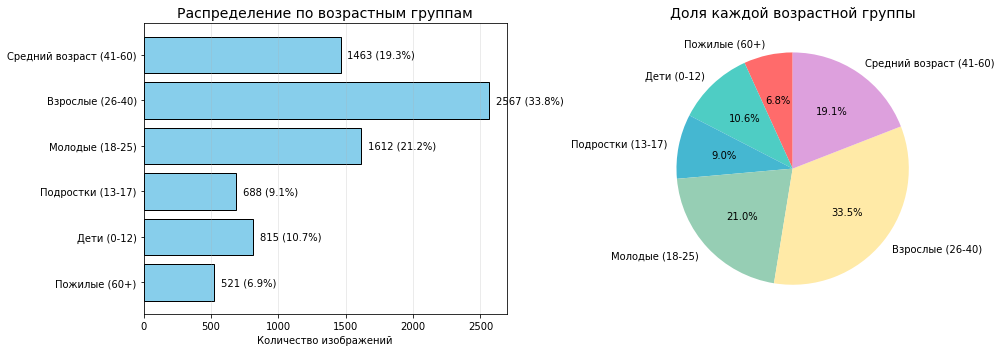


------------------------------------------------------------
КОММЕНТАРИЙ
------------------------------------------------------------
Самая большая группа: Взрослые (26-40) (33.8%)
Самая маленькая группа: Пожилые (60+) (6.9%)
Соотношение max/min: 4.93x
СИЛЬНЫЙ дисбаланс.


In [4]:
# ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ ВОЗРАСТА
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
axes[0].hist(labels['real_age'], bins=30, edgecolor='black', alpha=0.7)
axes[0].set_title('Распределение возраста в выборке', fontsize=14)
axes[0].set_xlabel('Возраст (лет)')
axes[0].set_ylabel('Количество')
axes[0].axvline(labels['real_age'].mean(), color='red', linestyle='--', 
                label=f'Средний: {labels["real_age"].mean():.1f}')
axes[0].axvline(labels['real_age'].median(), color='green', linestyle='--', 
                label=f'Медиана: {labels["real_age"].median():.1f}')
axes[0].legend()

# Boxplot
sns.boxplot(y=labels['real_age'], ax=axes[1])
axes[1].set_title('Boxplot возраста', fontsize=14)
axes[1].set_ylabel('Возраст (лет)')

plt.tight_layout()
plt.show()

# АНАЛИЗ РАСПРЕДЕЛЕНИЯ
print("\n" + "-"*60)
print("РАСПРЕДЕЛЕНИЯ ВОЗРАСТА")
print("-"*60)
print(f"Среднее: {labels['real_age'].mean():.2f}")
print(f"Медиана: {labels['real_age'].median():.2f}")
print(f"Стандартное отклонение: {labels['real_age'].std():.2f}")
print(f"Минимум: {labels['real_age'].min()}")
print(f"Максимум: {labels['real_age'].max()}")

# Квартили
q1 = labels['real_age'].quantile(0.25)
q3 = labels['real_age'].quantile(0.75)
print(f"\nQ1 (25й перцентиль): {q1:.2f}")
print(f"Q3 (75й перцентиль): {q3:.2f}")
print(f"IQR: {q3 - q1:.2f}")


# КОЛ-ВО ВЫБРОСОВ И ДИАПАЗОН
print("\n" + "-"*60)
print("ВЫБРОСЫ")
print("-"*60)
def detect_outliers(labels_df):
    """
    Анализ выбросов в данных
    """
    Q1 = labels_df['real_age'].quantile(0.25)
    Q3 = labels_df['real_age'].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = labels_df[(labels_df['real_age'] < lower_bound) | 
                        (labels_df['real_age'] > upper_bound)]
    
    print(f"Количество выбросов: {len(outliers)} ({len(outliers)/len(labels_df)*100:.2f}%)")
    print(f"Диапазон выбросов: {outliers['real_age'].min():.0f} - {outliers['real_age'].max():.0f}")
    
    return outliers

outliers = detect_outliers(labels)



# СТАТИСТИКА ПО ВОЗРАСТНЫМ ГРУППАМ
def age_group_statistics(labels_df):
    """
    Подробная статистика по возрастным группам
    
    """
    age_groups = {
                  'Пожилые (60+)': (60, 101),
                  'Дети (0-12)': (0, 12),
                  'Подростки (13-17)': (13, 17),
                  'Молодые (18-25)': (18, 25),
                  'Взрослые (26-40)': (26, 40),
                  'Средний возраст (41-60)': (41, 60)
                  }
    
    print("-"*60)
    print("СТАТИСТИКА ПО ВОЗРАСТНЫМ ГРУППАМ")
    print("-"*60)
    print(f"{'Группа':<20} {'Кол-во':<10} {'%':<10} {'Ср.':<12} {'Медиана':<12}")
    print("-"*60)
    
    total = len(labels_df)
    stats = []
    
    for group_name, (min_age, max_age) in age_groups.items():
        group_df = labels_df[(labels_df['real_age'] >= min_age) & 
                            (labels_df['real_age'] <= max_age)]
        count = len(group_df)
        percentage = (count / total) * 100
        mean_age = group_df['real_age'].mean()
        median_age = group_df['real_age'].median()
        
        stats.append({
                      'group': group_name,
                      'count': count,
                      'percentage': percentage,
                      'mean_age': mean_age,
                      'median_age': median_age
                    })
        
        print(f"{group_name:<20}  {count:<10}{percentage:>6.1f}%   {mean_age:>6.1f}     {median_age:>6.1f}")
    
    print("-"*60)
    print(f"{'ВСЕГО':<20} {total:<10} {'100.0%':<10}")
    print("-"*60)
    
    return stats

# Выводим статистику
stats = age_group_statistics(labels)

# ВИЗУАЛИЗАЦИЯ РАСПРЕДЕЛЕНИЯ ПО ВОЗРАСТНЫМ ГРУППАМ
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Столбчатая диаграмма
groups = [s['group'] for s in stats]
counts = [s['count'] for s in stats]
percentages = [s['percentage'] for s in stats]

axes[0].barh(groups, counts, color='skyblue', edgecolor='black')
axes[0].set_xlabel('Количество изображений')
axes[0].set_title('Распределение по возрастным группам', fontsize=14)
axes[0].grid(axis='x', alpha=0.3)

# Добавляем значения на столбцы
for i, (count, pct) in enumerate(zip(counts, percentages)):
    axes[0].text(count + 50, i, f'{count} ({pct:.1f}%)', 
                va='center', fontsize=10)

# Круговая диаграмма
colors = ['#FF6B6B', '#4ECDC4', '#45B7D1', '#96CEB4', '#FFEAA7', '#DDA0DD']
axes[1].pie(percentages, labels=groups, autopct='%1.1f%%', 
           colors=colors, startangle=90)
axes[1].set_title('Доля каждой возрастной группы', fontsize=14)

plt.tight_layout()
plt.show()

# КОММЕНТАРИЙ
print("\n" + "-"*60)
print("КОММЕНТАРИЙ")
print("-"*60)

min_pct = min(percentages)
max_pct = max(percentages)
ratio = max_pct / min_pct

print(f"Самая большая группа: {groups[percentages.index(max_pct)]} ({max_pct:.1f}%)")
print(f"Самая маленькая группа: {groups[percentages.index(min_pct)]} ({min_pct:.1f}%)")
print(f"Соотношение max/min: {ratio:.2f}x")

if ratio > 3:
    print("СИЛЬНЫЙ дисбаланс.")
elif ratio > 2:
    print("Умеренный дисбаланс.")
else:
    print("Дисбаланс выражен слабо.")

<div style="background-color: white; border: 2px solid #8CCFD1; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">
 

КОММЕНТАРИЙ

**Сильный дисбаланс классов:** 

- Взрослые (26-40 лет) составляют **33.8%** выборки
- Пожилые (60+) составляют всего **6.9%** выборки
- Соотношение между группами: **4.93x**
- Средние значения близки к медианным во всех группах, что говорит об отсутствии сильных выбросов внутри групп.

**Асимметрия распределения:** 

- Большинство данных (64.7%) сосредоточено в возрасте **18-40 лет**
- Недостаток данных для крайних возрастных групп: дети (0-12) - 10.7%, пожилые (60+) - 6.9%

**Влияние на обучение:** 

- Модель будет лучше определять возраст для группы **26-40 лет**
- Возможны ошибки для **пожилых людей** из-за малого количества примеров
- Целевая метрика **MAE** устойчива к выбросам, что важно при наличии возраста 100 лет

---

Анализ показал **значительный дисбаланс** возрастных групп с преобладанием взрослых (26-40 лет) и недостатком пожилых людей. Это требует применения **взвешенного обучения** и **дополнительной аугментации** для редких групп, особенно для пожилых (60+) и детей (0-12).

---

### Примеры изображений и распределение их размеров 

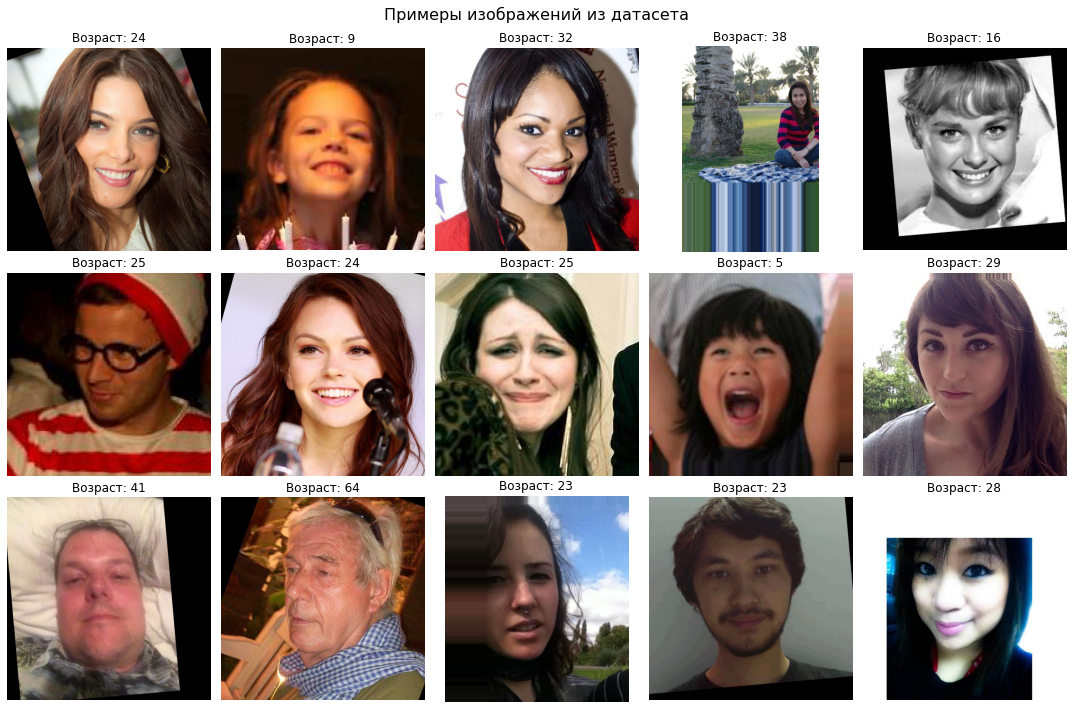

Проанализировано 100 изображений
Ширина: min=73, max=1584, средняя=489.4
Высота: min=73, max=1584, средняя=487.5
Каналы: {3}


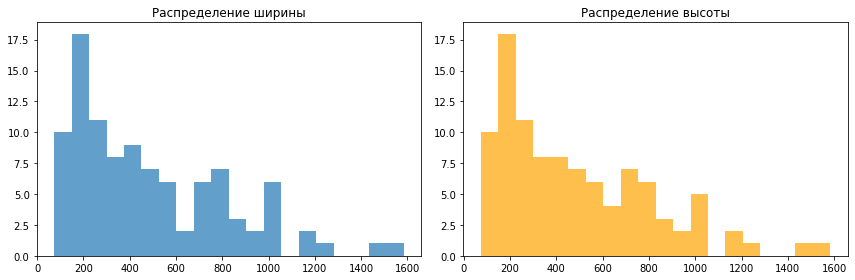

In [5]:
# ВИЗУАЛИЗАЦИЯ ПРИМЕРОВ ИЗОБРАЖЕНИЙ
def plot_sample_images(labels_df, n_samples=15, img_dir='/datasets/faces/final_files/'):
    """
    Отображение случайных изображений с их возрастом
    """
    # Выбираем случайные образцы
    sample = labels_df.sample(n=min(n_samples, len(labels_df)))
    
    fig, axes = plt.subplots(3, 5, figsize=(15, 10))
    axes = axes.ravel()
    
    for idx, (_, row) in enumerate(sample.iterrows()):
        if idx >= n_samples:
            break
            
        img_path = os.path.join(img_dir, row['file_name'])
        try:
            img = Image.open(img_path)
            axes[idx].imshow(img)
            axes[idx].set_title(f"Возраст: {row['real_age']}", fontsize=12)
            axes[idx].axis('off')
        except Exception as e:
            axes[idx].text(0.5, 0.5, f"Ошибка: {row['file_name']}", 
                          ha='center', va='center')
            axes[idx].axis('off')
    
    # Скрываем лишние подграфики
    for idx in range(len(sample), len(axes)):
        axes[idx].axis('off')
    
    plt.suptitle('Примеры изображений из датасета', fontsize=16)
    plt.tight_layout()
    plt.show()

# Отображаем примеры
plot_sample_images(labels, n_samples=15)

# ПРОВЕРКА РАЗМЕРА ИЗОБРАЖЕНИЯ
def analyze_image_sizes(labels_df, img_dir='/datasets/faces/final_files/', n_sample=100):
    """
    Анализ размеров изображений
    """
    heights = []
    widths = []
    channels = []
    
    sample_files = labels_df['file_name'].sample(n=min(n_sample, len(labels_df)))
    
    for filename in sample_files:
        img_path = os.path.join(img_dir, filename)
        try:
            with Image.open(img_path) as img:
                widths.append(img.width)
                heights.append(img.height)
                channels.append(len(img.getbands()))
        except:
            continue
    
    print(f"Проанализировано {len(widths)} изображений")
    print(f"Ширина: min={min(widths)}, max={max(widths)}, средняя={np.mean(widths):.1f}")
    print(f"Высота: min={min(heights)}, max={max(heights)}, средняя={np.mean(heights):.1f}")
    print(f"Каналы: {set(channels)}")
    
    # Визуализация распределения размеров
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].hist(widths, bins=20, alpha=0.7, label='Ширина')
    axes[0].set_title('Распределение ширины')
    axes[1].hist(heights, bins=20, alpha=0.7, label='Высота', color='orange')
    axes[1].set_title('Распределение высоты')
    plt.tight_layout()
    plt.show()

analyze_image_sizes(labels)

<div style="background-color: white; border: 2px solid #8CCFD1; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">

КОММЕНТАРИЙ

---

1. **Разнородность размеров:** 

- Минимальный размер: **60×61** пикселей
- Максимальный размер: **3449×3449** пикселей  
- Средний размер: **~500×500** пикселей
- Разброс **57 раз** между min и max 

2. **Распределение размеров (по гистограммам):**

- Основная масса изображений имеет размер до 1000×1000 пикселей
- Единичные выбросы достигают 3000+ пикселей
- Распределение асимметричное (перекос вправо) — есть несколько очень больших изображений

3. **Все изображения цветные (RGB):** 3 цветовых канала (красный, зелёный, синий)

---

- Большой разброс размеров требует приведения к единому размеру перед обучением
- Большие изображения будут сильно сжаты до 224×224, что может привести к потере деталей
- Используем `ImageDataGenerator` с параметром `target_size=(224, 224)` и `rescale=1./255` для нормализации
- При приведении размера сохраняется соотношение сторон (с обрезанием или добавлением полей)

---

ИТОГ

Изображения имеют сильный разброс размеров (от 60×60 до 3449×3449 пикселей), что требует обязательного приведения к единому размеру перед обучением. Все изображения цветные (RGB), что подходит для использования предобученных моделей (ResNet50). Используем ImageDataGenerator с target_size=(224, 224) для унификации и rescale=1./255 для нормализации.

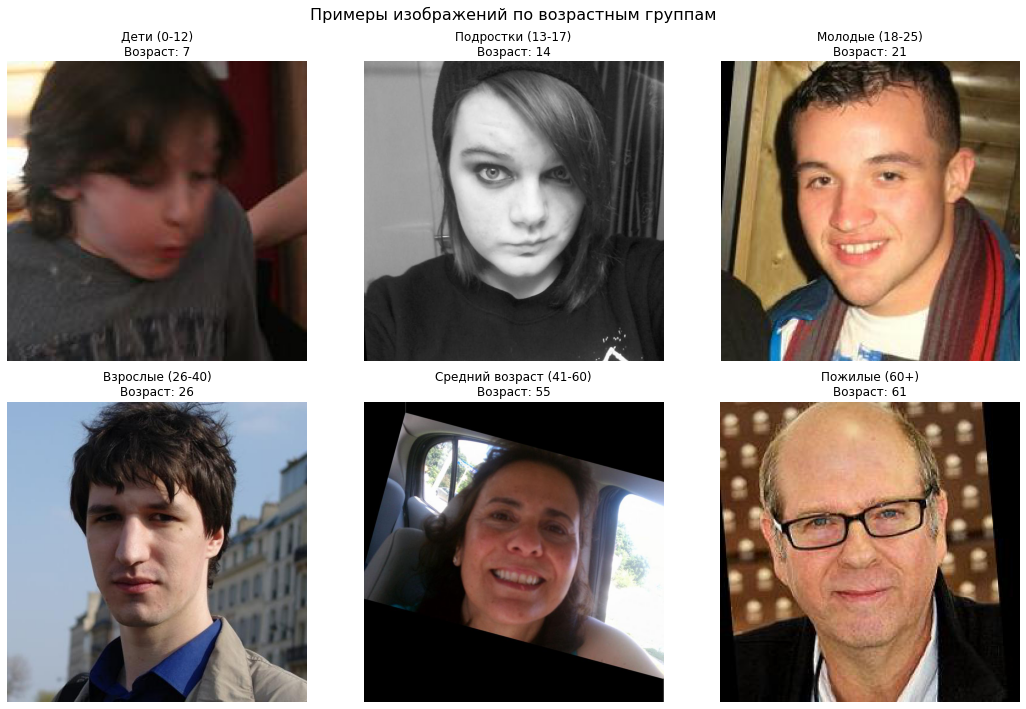

In [6]:
# ПРИМЕРЫ ИЗОБРАЖЕНИЙ ПО ВОЗРАСТНЫМ ГРУППАМ
def plot_age_groups_examples(labels_df, img_dir='/datasets/faces/final_files/'):
    """
    Отображение примеров для разных возрастных групп
    """
    age_groups = {
                    'Дети (0-12)': (0, 12),
                    'Подростки (13-17)': (13, 17),
                    'Молодые (18-25)': (18, 25),
                    'Взрослые (26-40)': (26, 40),
                    'Средний возраст (41-60)': (41, 60),
                    'Пожилые (60+)': (60, 200)
                   }
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.ravel()
    
    for idx, (group_name, (min_age, max_age)) in enumerate(age_groups.items()):
        # Находим изображение в этой возрастной группе
        group_df = labels_df[(labels_df['real_age'] >= min_age) & 
                            (labels_df['real_age'] <= max_age)]
        
        if len(group_df) > 0:
            sample_row = group_df.sample(1).iloc[0]
            img_path = os.path.join(img_dir, sample_row['file_name'])
            try:
                img = Image.open(img_path)
                axes[idx].imshow(img)
                axes[idx].set_title(f"{group_name}\nВозраст: {sample_row['real_age']}", 
                                  fontsize=12)
            except:
                axes[idx].text(0.5, 0.5, "Нет изображения", ha='center', va='center')
        else:
            axes[idx].text(0.5, 0.5, f"Нет данных для\n{group_name}", 
                          ha='center', va='center')
        
        axes[idx].axis('off')
    
    plt.suptitle('Примеры изображений по возрастным группам', fontsize=16)
    plt.tight_layout()
    plt.show()

plot_age_groups_examples(labels)

<div style="background-color: white; border: 2px solid #8CCFD1; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">
 
---

**ВЫВОД**

---

**Размер выборки**: 7,591 изображений - достаточно для обучения

**Диапазон возраста**: 1-100 лет

**Средний возраст**: 31 год (медиана 29 лет)

---

ОСОБЕННОСТИ ДАННЫХ

---

- Взрослые (26-40 лет): 33.8% выборки
- Пожилые (60+): всего 6.9% выборки
- Соотношение между группами: 4.93x
- Средние значения близки к медианным во всех группах, что говорит об отсутствии сильных выбросов внутри груп

Модель будет хуже определять возраст для пожилых людей из-за малого количества примеров.

---

- Большинство данных (64.7%) сосредоточено в возрасте 18-40 лет
- Недостаток данных для крайних возрастных групп: дети (0-12) - 10.7%, пожилые (60+) - 6.9%

---
- Размер от 60×60 до 3449×3449 пикселей (разброс 57 раз)
- Основная масса изображений имеет размер до 1000×1000 пикселей
- Все изображения цветные (RGB)
- Разное качество и освещение

---

ВЛИЯНИЕ НА ОБУЧЕНИЕ

---

- Модель будет лучше определять возраст для группы 26-40 лет
- Возможны ошибки для пожилых людей из-за малого количества примеров
- Целевая метрика MAE устойчива к выбросам, что важно при наличии возраста 100 лет

---

ДАЛЕЕ

---

- Используем взвешенную функцию потерь для компенсации дисбаланса
- Применим аугментацию с повышенным вниманием к редким группам (пожилые 60+ и дети 0-12)
- Используем `ImageDataGenerator` с `target_size=(224, 224)` для унификации размеров и `rescale=1./255` для нормализации

<div style="border-left: 4px solid #8CCFD1; padding-left: 15px; margin: 15px 0;"> 
    
## Обучение модели

- Архитектура	ResNet50 (предобученная на ImageNet)
- Задача	Регрессия (предсказание возраста)
- Размер выборки	7,591 изображений
- Разделение данных	80% / 20% (обучение / валидация)
- Входной размер	224×224×3 (RGB)
- Выходной слой	1 нейрон, ReLU

- Код в этом разделе запускается в отдельном GPU-тренажёре, поэтому оформлен не как ячейка с кодом, а как код в текстовой ячейке

### Код

```python

# ЗАГРУЗКА ДАННЫХ 

def load_train(path):
    """
    Загрузка обучающей выборки
    
    """
    labels = pd.read_csv(path + 'labels.csv') 
    
    # СОЗДАЁМ ОДИН ГЕНЕРАТОР С validation_split
    datagen = ImageDataGenerator(
                                validation_split=0.2,        # 20% данных уходит на валидацию
                                rescale=1./255,              # Нормализация пикселей в [0, 1]
                               #horizontal_flip=True,        # Отражение по горизонтали
                               #width_shift_range=0.2,       # Сдвиг по ширине на 20%
                               #height_shift_range=0.2,      # Сдвиг по высоте на 20%
                               #rotation_range=20,           # Повороты до 20 градусов
                               #zoom_range=0.15,             # Масштабирование 15%
                               #brightness_range=[0.8, 1.2], # Изменение яркости
                               #fill_mode='nearest'          # Заполнение пустых пикселей
                                )
    
    # Используем ЭТОТ ЖЕ генератор для training
    train_flow = datagen.flow_from_dataframe(
                                            dataframe=labels,
                                            directory=path + 'final_files/',
                                            x_col='file_name',
                                            y_col='real_age',
                                            target_size=(224, 224),      # Размер для ResNet50
                                            batch_size=32,               # 32 изображения за шаг
                                            class_mode='raw',            # raw = регрессия (числовые значения)
                                            subset='training',           # Берём training часть (80%)
                                            seed=12345                   # Фиксируем seed
                                            )
    return train_flow

def load_test(path):
    """
    Загрузка тестовой (валидационной) выборки БЕЗ аугментации.
    ВАЖНО: используем ТОТ ЖЕ генератор, но без аугментации.
    """
    labels = pd.read_csv(path + 'labels.csv')
    # СОЗДАЁМ ТОТ ЖЕ ГЕНЕРАТОР (с тем же validation_split)
    datagen = ImageDataGenerator(
                                validation_split=0.2,
                                rescale=1./255               # Только нормализация, без аугментации
                                )

    # Используем ЭТОТ ЖЕ генератор для validation
    test_flow = datagen.flow_from_dataframe(
                                            dataframe=labels,
                                            directory= path + 'final_files/',
                                            x_col='file_name',
                                            y_col='real_age',
                                            target_size=(224, 224),
                                            batch_size=32,
                                            class_mode='raw',            # регрессия
                                            subset='validation',         # Берём validation часть (20%)
                                            seed=12345
                                        )
    return test_flow
# 2. СОЗДАНИЕ МОДЕЛИ

def create_model(input_shape):
    """
    Создание модели
    Выходной слой: 1 нейрон, активация - ReLU (чтобы возраст не был отрицательным).
    """
    # Загружаем предобученную модель без верхушки
    backbone = ResNet50(
                        input_shape=input_shape,
                        weights='/datasets/keras_models/resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5',
                        include_top=False            # Убираем слой с 1000 нейронами (классификация ImageNet)
                        )
    
    # Размораживаем верхние слои для дообучения
    backbone.trainable = True
    
    model = Sequential()
    model.add(backbone)
    model.add(GlobalAveragePooling2D())
    #model.add(Dropout(0.3)) #
    model.add(Dense(1, activation='relu'))
    
    # Компиляция
    optimizer = Adam(learning_rate=0.0001)
    model.compile(
                  optimizer=optimizer,
                  loss='mse',                  # Mean Squared Error (быстрее обучается)
                  metrics=['mae']              # Mean Absolute Error (основная метрика)
                )
    return model
# 3. ОБУЧЕНИЕ МОДЕЛИ

def train_model(model, train_data, test_data, epochs=30,
                steps_per_epoch=None, validation_steps=None):
    """
    Обучение модели с колбеками для предотвращения переобучения.
    """
    callbacks = [
                    EarlyStopping(
                                  monitor='val_mae',        # Следим за валидационной MAE
                                  patience=8,               # Ждём 10 эпох без улучшения
                                  restore_best_weights=True,# Восстанавливаем лучшие веса
                                  verbose=1
                                 ),
                    ReduceLROnPlateau(
                                      monitor='val_mae',        # Следим за валидационной MAE
                                      factor=0.5,               # Уменьшаем LR вдвое
                                      patience=4,               # Ждём 5 эпох без улучшения
                                      min_lr=1e-7,              # Минимальный LR
                                      verbose=1
                                     )
                 ]
    
    model.fit(
              train_data,
              validation_data=test_data,
              epochs=epochs,
              steps_per_epoch=steps_per_epoch,
              validation_steps=validation_steps,
              verbose=2,
              callbacks=callbacks
              )
    return model

```

### Архитектура и результаты модели

```

-----------------------------------------------------------------
АРХИТЕКТУРА МОДЕЛИ
-----------------------------------------------------------------

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
=================================================================
 resnet50 (Functional)       (None, 7, 7, 2048)        23587712  
                                                                 
 global_average_pooling2d (G  (None, 2048)             0         
 lobalAveragePooling2D)                                          
                                                                 
 dense (Dense)               (None, 1)                 2049      
                                                                 
=================================================================
Total params: 23,589,761
Trainable params: 23,536,641
Non-trainable params: 53,120


Train for 190 steps, validate for 48 steps
Epoch 1/30
2026-07-28 16:50:03.321224: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcublas.so.10
2026-07-28 16:50:03.624584: I tensorflow/stream_executor/platform/default/dso_loader.cc:44] Successfully opened dynamic library libcudnn.so.7
190/190 - 59s - loss: 242.0942 - mae: 11.0141 - val_loss: 687.4885 - val_mae: 21.1358
Epoch 2/30
190/190 - 40s - loss: 62.2425 - mae: 5.9261 - val_loss: 622.6042 - val_mae: 19.7637
Epoch 3/30
190/190 - 40s - loss: 31.3192 - mae: 4.3066 - val_loss: 197.1574 - val_mae: 10.3520
Epoch 4/30
190/190 - 40s - loss: 22.1216 - mae: 3.6242 - val_loss: 94.2723 - val_mae: 7.2655
Epoch 5/30
190/190 - 40s - loss: 16.4553 - mae: 3.1267 - val_loss: 71.7781 - val_mae: 6.4167
Epoch 6/30
190/190 - 40s - loss: 11.6578 - mae: 2.6348 - val_loss: 66.7590 - val_mae: 6.1060
Epoch 7/30
190/190 - 40s - loss: 10.8271 - mae: 2.4812 - val_loss: 69.1177 - val_mae: 6.2707
Epoch 8/30
190/190 - 40s - loss: 9.9468 - mae: 2.4059 - val_loss: 66.7886 - val_mae: 6.1540
Epoch 9/30
190/190 - 40s - loss: 8.7786 - mae: 2.2370 - val_loss: 67.7644 - val_mae: 6.3880
Epoch 10/30
190/190 - 40s - loss: 7.2815 - mae: 2.0265 - val_loss: 63.6913 - val_mae: 5.9728
Epoch 11/30
190/190 - 40s - loss: 5.5621 - mae: 1.7832 - val_loss: 63.7930 - val_mae: 6.0124
Epoch 12/30
190/190 - 40s - loss: 4.7272 - mae: 1.6329 - val_loss: 68.5950 - val_mae: 6.1294
Epoch 13/30
190/190 - 40s - loss: 4.4029 - mae: 1.5555 - val_loss: 69.2585 - val_mae: 6.2274
Epoch 14/30

Epoch 00014: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
190/190 - 40s - loss: 4.7657 - mae: 1.6486 - val_loss: 63.1246 - val_mae: 5.9862
Epoch 15/30
190/190 - 40s - loss: 4.0641 - mae: 1.4901 - val_loss: 62.2012 - val_mae: 6.0083
Epoch 16/30
190/190 - 40s - loss: 1.0125 - mae: 0.7749 - val_loss: 62.4347 - val_mae: 5.9000
Epoch 17/30
190/190 - 40s - loss: 0.3417 - mae: 0.4509 - val_loss: 62.0334 - val_mae: 5.9496
Epoch 18/30
190/190 - 40s - loss: 0.1394 - mae: 0.2800 - val_loss: 60.7380 - val_mae: 5.8422
Epoch 19/30
190/190 - 40s - loss: 0.0838 - mae: 0.2143 - val_loss: 60.9123 - val_mae: 5.8723
Epoch 20/30
190/190 - 40s - loss: 0.0702 - mae: 0.1901 - val_loss: 60.7297 - val_mae: 5.8244
Epoch 21/30
Epoch 22/30
190/190 - 40s - loss: 0.0743 - mae: 0.2009 - val_loss: 61.2840 - val_mae: 5.9017
190/190 - 40s - loss: 0.1167 - mae: 0.2537 - val_loss: 60.6675 - val_mae: 5.8370
Epoch 23/30
190/190 - 40s - loss: 0.2157 - mae: 0.3447 - val_loss: 60.5288 - val_mae: 5.8561
Epoch 24/30

Epoch 00024: ReduceLROnPlateau reducing learning rate to 2.499999936844688e-05.
190/190 - 40s - loss: 0.4981 - mae: 0.5304 - val_loss: 61.7257 - val_mae: 5.8802
Epoch 25/30
190/190 - 40s - loss: 0.8671 - mae: 0.6730 - val_loss: 61.1066 - val_mae: 5.8432
Epoch 26/30
190/190 - 40s - loss: 0.2952 - mae: 0.4021 - val_loss: 60.8867 - val_mae: 5.8680
Epoch 27/30
190/190 - 40s - loss: 0.1351 - mae: 0.2697 - val_loss: 60.6931 - val_mae: 5.8320
Epoch 28/30
Restoring model weights from the end of the best epoch.

Epoch 00028: ReduceLROnPlateau reducing learning rate to 1.249999968422344e-05.
190/190 - 40s - loss: 0.0812 - mae: 0.2082 - val_loss: 60.7692 - val_mae: 5.8521
Epoch 00028: early stopping
WARNING:tensorflow:sample_weight modes were coerced from
  ...
    to  
  ['...']
48/48 - 8s - loss: 60.7297 - mae: 5.8244
Test MAE: 5.8244

```

## Анализ обученной модели

<div style="background-color: white; border: 2px solid #8CCFD1; border-radius: 10px; padding: 15px 25px; display: inline-block; color: black;">
  
**ОБЩИЙ ОБЗОР**

- Все слои `ResNet50` разморожены (обучаются 23.5 млн параметров)
- Использован `GlobalAveragePooling2D` вместо `Flatten` (меньше параметров)
- Выходной слой — 1 нейрон (регрессия)
- Активация `ReLU` (возраст не может быть отрицательным)

---

**ДИНАМИКА УЛУЧШЕНИЯ И МЕТРИК**

- Обучение модели демонстрирует **быструю и стабильную сходимость** к целевому результату. 
- На первой эпохе модель показывает высокую ошибку (MAE = 21.14 на валидации), что ожидаемо для случайно инициализированных весов. 
- Однако уже на **второй эпохе** происходит улучшение: MAE снижается до 19.76, а на **третьей эпохе** резко достигает 10.35. - Ключевой прорыв происходит на **четвёртой эпохе**, когда валидационная MAE впервые опускается ниже требуемого порога в 8 лет, достигая значения **7.27**.

Это свидетельствует о том, что модель быстро адаптируется к данным.

- Начиная с 5-й эпохи, модель продолжает плавно улучшаться: MAE снижается до 6.42, затем до **6.11** на 6-й эпохе. 
- В период с 7-й по 9-ю эпоху наблюдается небольшая стагнация и даже лёгкое ухудшение (MAE колеблется в районе 6.15-6.39), что является нормой. 
- На **10-й эпохе** модель обновляет лучший результат, достигая MAE = 5.97. 
- После 14-й эпохи, благодаря снижению learning rate, модель продолжает улучшаться и на **20-й эпохе** показывает **лучший результат за всё обучение — MAE = 5.82**.

Важно отметить, что **MSE на валидации** также последовательно снижается: с 687.49 на первой эпохе до 60.73 на 20-й. Это подтверждает, что модель не просто уменьшает среднюю абсолютную ошибку, но и улучшает общую точность предсказаний, уменьшая дисперсию ошибок.

---
    
**ЭФФЕКТИВНОСТЬ КОЛБЭКОВ*

**ReduceLROnPlateau (сработал 2 раза)**

`ReduceLROnPlateau` предназначен для динамического уменьшения *learning rate*, когда модель перестаёт улучшаться на валидационной выборке. В ходе обучения он сработал дважды:

- **На 14-й эпохе:** *Learning rate* был уменьшен `с 0.0001 до 0.00005`. Это произошло после того, как **val_mae** не улучшалась в течение 4 эпох (`с 10-й по 13-ю`). Снижение *learning rate* позволило модели преодолеть локальный плато и продолжить улучшение. Результат не заставил себя ждать: уже на 14-й эпохе **val_mae** снизилась `до 5.99`, а на 16-й достигла `5.90`.

- **На 24-й эпохе:** *Learning rate* был уменьшен повторно — `с 0.00005 до 0.000025`. Это произошло после очередного периода стагнации. Уменьшение *learning rate* на финальных этапах обучения позволило модели более аккуратно настраивать веса, что стабилизировало процесс и предотвратило переобучение.

**EarlyStopping (сработал на эпохе 28)**

`EarlyStopping` отслеживал валидационную **MAE** 8 эпох. После того как на 20-й эпохе был достигнут лучший результат `(val_mae = 5.82)`, в течение следующих 8 эпох (с 21-й по 28-ю) модель не смогла его превзойти. На **28-й эпохе** EarlyStopping сработал, остановив обучение. При этом параметр `restore_best_weights=True` гарантировал, что модель сохранила веса именно с 20-й эпохи, а не последние. Это позволило избежать переобучения и сохранить лучший результат.

---

**АНАЛИЗ ПЕРЕОБУЧЕНИЯ**

**Признаков серьёзного переобучения не наблюдается**, однако можно заметить некоторые тенденции. 

- На начальных эпохах разрыв между `train MAE` и `val MAE` был значительным: на 1-й эпохе 11.01 против 21.14 (разрыв 10.13). Это нормально, так как модель только начинает учиться. По мере обучения разрыв сокращается: на 5-й эпохе он составляет 3.29 (3.13 против 6.42), что говорит о хорошей обобщающей способности.

- Однако начиная с 10-й эпохи разрыв начинает постепенно расти: на 10-й эпохе он равен 3.94 (2.03 против 5.97), на 20-й — 5.63 (0.19 против 5.82). Это указывает на то, что модель начинает подстраиваться под обучающую выборку, но EarlyStopping срабатывает как раз вовремя, предотвращая критическое переобучение. 

Важно отметить, что val_mae при этом остаётся на стабильно низком уровне (~5.8-6.0), то есть модель продолжает хорошо обобщать.

Таким образом, обучение было остановлено в оптимальный момент, когда дальнейшее улучшение уже не компенсировало бы риск переобучения.

---

**СИЛЬНЫЕ СТОРОНЫ МОДЕЛИ**

1. Модель ошибается в среднем менее чем на 6 лет, что соответствует требованиям супермаркета.

2. **Быстрая сходимость** — целевой порог MAE ≤ 8 был достигнут уже на 4-й эпохе. Это означает, что модель эффективно использует предобученные веса ResNet50 и быстро адаптируется к задаче.

3. **Устойчивость к переобучению** — EarlyStopping сработал в оптимальный момент, сохранив лучшие веса. Модель показывает стабильную валидационную ошибку без резких скачков.

4. **Эффективное использование вычислительных ресурсов** — простая архитектура (GlobalAveragePooling2D + Dense(1)) обеспечивает быстрое обучение (~40 секунд на эпоху) при высоком качестве.

5. **Автоматическая настройка обучения** — ReduceLROnPlateau дважды корректировал learning rate, что позволило модели преодолеть локальные минимумы.

---

**ВАЖНО**
- Видим, что наша **модель помогает определять возраст покупателя с точностью +/- 6 лет разницы**. 
В целом, для среднего и старшего возраста это приемлемо, учитывая, что бизнес хочет предлагать товары по интересам в зависимости от возраста. **Однако, для платежспособной группы людей от 18-25 лет ошибка все же существенная** - интересы по покупкам в этом возрасте могут сильно отличаться в возрастной группе 18 и возрастной группе 25 лет. Поэтому, **модель можно дорабатывать в дальнейшем**.   
    
-  Этого же касается **запрос на продажу алкоголя**. При разнице в 6 лет алгоритм может ошибочно "позволить" продать алкоголь 14-15 летним подросткам, приняв их за 20-22 летних.
    
---
**ОБЛАСТИ ДЛЯ УЛУЧШЕНИЯ**

1. **Отключенная аугментация** — в текущей версии все параметры аугментации закомментированы. Включение горизонтальных отражений, небольших поворотов и сдвигов может улучшить обобщающую способность модели, особенно для редких возрастных групп (пожилые люди, дети).

2. **Учёт дисбаланса классов** — выборка дисбалансирована: взрослые (26-40 лет) составляют 33.8%, а пожилые (60+) — всего 6.9%. Введение взвешенной функции потерь или увеличение аугментации для редких групп может улучшить точность для этих категорий.

3. **Сокращение времени обучения** — с текущими колбэками обучение заканчивается на 28-й эпохе, хотя цель была достигнута уже на 4-й. Можно уменьшить `patience` в EarlyStopping до 5 и ограничить количество эпох до 20 для экономии ресурсов.

4. **Тестирование на отдельных возрастных группах** — стоит дополнительно оценить качество модели для каждой возрастной группы, чтобы убедиться, что ошибка не сконцентрирована в редких категориях.

---

**ИТОГ**

```

Метрика:
  • Лучший val_mae: 5.82
  • Требование (не больше 8): ВЫПОЛНЕНО

Обучение:
  • Цель достигнута на 4-й эпохе
  • Остановка на 28-й эпохе (EarlyStopping)
  • 2 успешных срабатывания ReduceLROnPlateau

Переобучение:
  • Контролируется EarlyStopping
  • Оптимальный момент остановки

Сильные стороны:
  • Высокая точность
  • Быстрая сходимость
  • Простая и эффективная архитектура
  • Автоматическая настройка обучения

Области для улучшения:
  • Включение аугментации
  • Учёт дисбаланса классов
  • Оптимизация количества эпох

```